# Telco Customer Churn — Final Model Evaluation

## Objective

This notebook finalizes the selected XGBoost model.

The main objectives are:
- Load the selected model configuration.
- Generate out-of-fold training predictions.
- Optimize the classification threshold.
- Refit the final pipeline on the full training set.
- Evaluate generalization on the untouched test set.
- Save the final model and evaluation artifacts.
- Track final results using MLflow.

The test set is used only after model and
threshold selection are complete.

In [1]:
from pathlib import Path
import json
import joblib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_predict

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    precision_recall_curve,
    PrecisionRecallDisplay
)


from xgboost import XGBClassifier

import mlflow
from mlflow.tracking import MlflowClient

# Project root
project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Existing artifacts
bundle_path = (
    project_root / "data" / "processed"
    / "training_bundle.joblib"
)

params_path = (
    project_root / "results"
    / "05_best_params.json"
)

configs_path = (
    project_root / "results"
    / "05_best_model_configs.json"
)

for path in [bundle_path, params_path, configs_path]:
    print(path.relative_to(project_root), ":", path.exists())

data\processed\training_bundle.joblib : True
results\05_best_params.json : True
results\05_best_model_configs.json : True


In [2]:
bundle = joblib.load(bundle_path)

print("Available keys:", list(bundle.keys()))

X_train = bundle["X_train"]
y_train = bundle["y_train"]

preprocessor_tree = bundle["preprocessor_tree"]
cv = bundle["cv"]

print("\nTraining features:", X_train.shape)
print("Training labels:", y_train.shape)

print("\nClass distribution:")
print(y_train.value_counts(normalize=True))

print("\nPreprocessor:")
print(type(preprocessor_tree).__name__)

print("\nCross-validation:")
print(cv)

Available keys: ['X_train', 'y_train', 'preprocessor_tree', 'cv']

Training features: (5634, 19)
Training labels: (5634,)

Class distribution:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Preprocessor:
ColumnTransformer

Cross-validation:
StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


In [3]:
with open(params_path, "r", encoding="utf-8") as f:
    best_params = json.load(f)

with open(configs_path, "r", encoding="utf-8") as f:
    best_configs = json.load(f)

print("Best parameters:")
print(json.dumps(best_params, indent=2))

print("\nBest model configurations:")
print(json.dumps(best_configs, indent=2))

Best parameters:
{
  "XGBoost": {
    "n_estimators": 150,
    "max_depth": 2,
    "learning_rate": 0.08315510161972098,
    "subsample": 0.7996257787814657,
    "colsample_bytree": 0.6353718081178203,
    "min_child_weight": 3
  },
  "GradientBoosting": {
    "n_estimators": 150,
    "learning_rate": 0.02655331725728516,
    "max_depth": 4,
    "min_samples_leaf": 1,
    "subsample": 0.7103454500437947,
    "max_features": 0.7384072304692317
  }
}

Best model configurations:
{
  "XGBoost": {
    "n_estimators": 150,
    "max_depth": 2,
    "learning_rate": 0.08315510161972098,
    "subsample": 0.7996257787814657,
    "colsample_bytree": 0.6353718081178203,
    "min_child_weight": 3,
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "tree_method": "hist",
    "random_state": 42,
    "n_jobs": -1
  },
  "GradientBoosting": {
    "n_estimators": 150,
    "learning_rate": 0.02655331725728516,
    "max_depth": 4,
    "min_samples_leaf": 1,
    "subsample": 0.71034545004

## 2. Out-of-Fold Predictions

We generate out-of-fold predicted probabilities
using the optimized XGBoost model.

Each training observation is predicted by a model
trained without that observation.

The preprocessing pipeline is fitted separately
within each training fold to prevent data leakage.

These predictions will be used for classification
threshold optimization.

In [4]:


# Load optimized XGBoost configuration
xgb_config = best_configs["XGBoost"].copy()

# Build the final model pipeline
xgb_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor_tree)),
    ("model", XGBClassifier(**xgb_config))
])

print(xgb_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                              

In [5]:
# Generate OOF probabilities
oof_proba = cross_val_predict(
    estimator=xgb_pipeline,
    X=X_train,
    y=y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

print("Number of predictions:", len(oof_proba))
print("Minimum probability:", oof_proba.min())
print("Maximum probability:", oof_proba.max())

Number of predictions: 5634
Minimum probability: 0.001810891
Maximum probability: 0.93747085


In [6]:
# Validate predictions
assert len(oof_proba) == len(y_train)
assert np.isfinite(oof_proba).all()
assert ((oof_proba >= 0) & (oof_proba <= 1)).all()

# Calculate OOF metrics
oof_ap = average_precision_score(y_train, oof_proba)
oof_auc = roc_auc_score(y_train, oof_proba)

print(f"OOF Average Precision: {oof_ap:.4f}")
print(f"OOF ROC-AUC:          {oof_auc:.4f}")

# Store predictions for threshold optimization
oof_df = pd.DataFrame({
    "y_true": np.asarray(y_train),
    "churn_probability": oof_proba
})

display(oof_df.head())

OOF Average Precision: 0.6715
OOF ROC-AUC:          0.8503


,y_true,churn_probability
0,0,0.325310
1,0,0.313418
2,0,0.012571
3,0,0.049226
4,0,0.576727


## 3. Classification Threshold Optimization

The default classification threshold of 0.5 is not
necessarily optimal for customer churn prediction.

We evaluate different thresholds using OOF
probabilities from the training set.

Metrics:
- Precision
- Recall
- F1-score
- False Positives and False Negatives
- Number of predicted churners

The test set remains untouched during threshold selection.

In [7]:
def evaluate_threshold(y_true, y_proba, threshold):

    y_pred = (np.asarray(y_proba) >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    return {
        "threshold": threshold,
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "alerts": int(y_pred.sum()),
        "tp": int(tp),
        "fp": int(fp),
        "fn": int(fn),
        "tn": int(tn),
    }


thresholds = np.arange(0.20, 0.71, 0.05)

threshold_results = pd.DataFrame([
    evaluate_threshold(y_train, oof_proba, t)
    for t in thresholds
])

display(threshold_results.round(4))

,threshold,precision,recall,f1,alerts,tp,fp,fn,tn
0,0.20,0.4797,0.8689,0.6181,2708,1299,1409,196,2730
1,0.25,0.5112,0.8234,0.6308,2408,1231,1177,264,2962
2,0.30,0.5424,0.7779,0.6392,2144,1163,981,332,3158
3,0.35,0.5723,0.7171,0.6366,1873,1072,801,423,3338
4,0.40,0.6067,0.6542,0.6295,1612,978,634,517,3505
5,0.45,0.6492,0.5967,0.6218,1374,892,482,603,3657
6,0.50,0.6718,0.5298,0.5924,1179,792,387,703,3752
7,0.55,0.6980,0.4575,0.5527,980,684,296,811,3843
8,0.60,0.7233,0.3759,0.4947,777,562,215,933,3924
9,0.65,0.7545,0.3064,0.4358,607,458,149,1037,3990


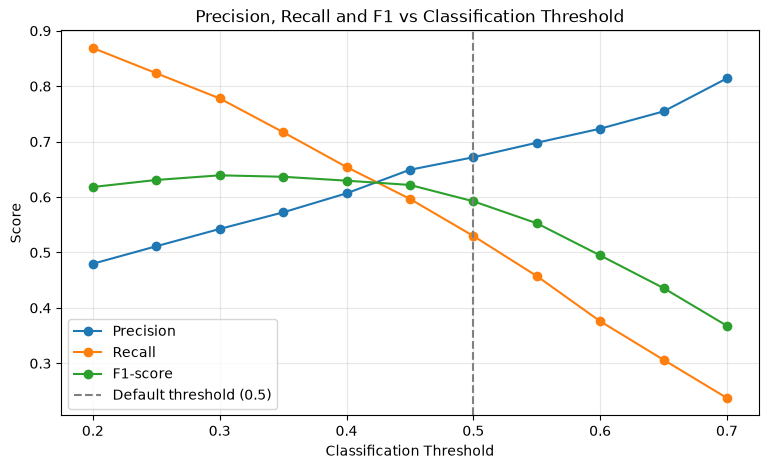

In [8]:


plt.figure(figsize=(9, 5))

plt.plot(
    threshold_results["threshold"],
    threshold_results["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["threshold"],
    threshold_results["f1"],
    marker="o",
    label="F1-score"
)

plt.axvline(
    0.5,
    color="gray",
    linestyle="--",
    label="Default threshold (0.5)"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 vs Classification Threshold")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [9]:

precision, recall, pr_thresholds = precision_recall_curve(
    y_train,
    oof_proba
)

# The final precision/recall pair has no corresponding threshold
precision = precision[:-1]
recall = recall[:-1]

f1_scores = (
    2 * precision * recall /
    (precision + recall + 1e-12)
)

best_idx = np.argmax(f1_scores)

best_threshold = float(pr_thresholds[best_idx])

print(f"Best threshold: {best_threshold:.6f}")
print(f"Precision:      {precision[best_idx]:.4f}")
print(f"Recall:         {recall[best_idx]:.4f}")
print(f"F1-score:       {f1_scores[best_idx]:.4f}")

Best threshold: 0.287234
Precision:      0.5371
Recall:         0.7940
F1-score:       0.6408


In [10]:
comparison = pd.DataFrame([
    evaluate_threshold(y_train, oof_proba, 0.5),
    evaluate_threshold(y_train, oof_proba, best_threshold)
])

comparison.insert(
    0,
    "strategy",
    ["Default (0.5)", "Best F1"]
)

display(comparison.round(4))

,strategy,threshold,precision,recall,f1,alerts,tp,fp,fn,tn
0,Default (0.5),0.5000,0.6718,0.5298,0.5924,1179,792,387,703,3752
1,Best F1,0.2872,0.5371,0.7940,0.6408,2210,1187,1023,308,3116


## 4. Final Model Training

The optimized XGBoost pipeline is refitted on the
entire training set after hyperparameter and
threshold selection.

The classification threshold was selected using
out-of-fold predictions and is kept fixed.

The held-out test set is not used during fitting
or threshold selection.

In [11]:

# Clone the optimized, unfitted pipeline
final_pipeline = clone(xgb_pipeline)

# Fit on the entire training set
final_pipeline.fit(X_train, y_train)

print("Final model trained successfully.")
print("Training samples:", len(X_train))
print("Number of features:", X_train.shape[1])
print(f"Selected threshold: {best_threshold:.6f}")

Final model trained successfully.
Training samples: 5634
Number of features: 19
Selected threshold: 0.287234


In [12]:
# Create models directory
models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)

model_path = models_dir / "final_churn_model.joblib"

# Package the final model
final_artifact = {
    "pipeline": final_pipeline,
    "threshold": float(best_threshold),
    "feature_names": X_train.columns.tolist(),
    "positive_class": 1,
}

joblib.dump(final_artifact, model_path)

print("Final model saved to:", model_path)

Final model saved to: C:\Users\Lenovo\Desktop\DS\Customer_Churn\Teleco_Customer_Churn\models\final_churn_model.joblib


In [13]:
# Reload saved artifact
loaded_artifact = joblib.load(model_path)

loaded_pipeline = loaded_artifact["pipeline"]
loaded_threshold = loaded_artifact["threshold"]

# Verify predictions are identical after reloading
original_proba = final_pipeline.predict_proba(
    X_train.head()
)[:, 1]

loaded_proba = loaded_pipeline.predict_proba(
    X_train.head()
)[:, 1]

assert np.allclose(original_proba, loaded_proba)
assert np.isclose(best_threshold, loaded_threshold)

print("Model reload verification: PASSED")
print("Saved threshold:", loaded_threshold)

Model reload verification: PASSED
Saved threshold: 0.2872343361377716


## 5. Final Test Set Evaluation

In [14]:
import sys
from sklearn.model_selection import train_test_split

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.preprocessing import clean_telco_data

# Load and clean the original dataset
raw_path = (
    project_root / "data" / "raw"
    / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
)

df = clean_telco_data(pd.read_csv(raw_path))

# Reproduce the original split
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["Churn"]
)

# Reconstruct training data for verification
X_train_check = train_df.drop(
    columns=["customerID", "Churn"]
)
y_train_check = train_df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Confirm we recovered the EXACT original training data
assert X_train_check.equals(X_train)
assert y_train_check.equals(y_train)

# Prepare held-out test data
X_test = test_df.drop(columns=["customerID", "Churn"])

y_test = test_df["Churn"].map({
    "No": 0,
    "Yes": 1
})

assert X_test.columns.tolist() == loaded_artifact["feature_names"]
assert X_train.index.intersection(X_test.index).empty
assert len(X_test) == 1409

print("Original split verification: PASSED")
print("Test features:", X_test.shape)
print("Test labels:", y_test.shape)
print("\nTest class distribution:")
print(y_test.value_counts(normalize=True))

Original split verification: PASSED
Test features: (1409, 19)
Test labels: (1409,)

Test class distribution:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


In [15]:
# Predict churn probabilities
test_proba = loaded_pipeline.predict_proba(X_test)[:, 1]

# Apply the selected OOF threshold
test_pred = (test_proba >= loaded_threshold).astype(int)

print("Test predictions:", len(test_pred))
print("Predicted churners:", test_pred.sum())
print("Predicted non-churners:", (test_pred == 0).sum())

Test predictions: 1409
Predicted churners: 570
Predicted non-churners: 839


In [16]:


test_metrics = {
    "average_precision": average_precision_score(
        y_test, test_proba
    ),
    "roc_auc": roc_auc_score(
        y_test, test_proba
    ),
    "precision": precision_score(
        y_test, test_pred, zero_division=0
    ),
    "recall": recall_score(
        y_test, test_pred, zero_division=0
    ),
    "f1": f1_score(
        y_test, test_pred, zero_division=0
    ),
    "balanced_accuracy": balanced_accuracy_score(
        y_test, test_pred
    )
}

print("FINAL TEST RESULTS")
print("-" * 35)

for metric, value in test_metrics.items():
    print(f"{metric:<20}: {value:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, test_pred))

FINAL TEST RESULTS
-----------------------------------
average_precision   : 0.6646
roc_auc             : 0.8458
precision           : 0.5158
recall              : 0.7861
f1                  : 0.6229
balanced_accuracy   : 0.7597

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.73      0.81      1035
           1       0.52      0.79      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.76      1409



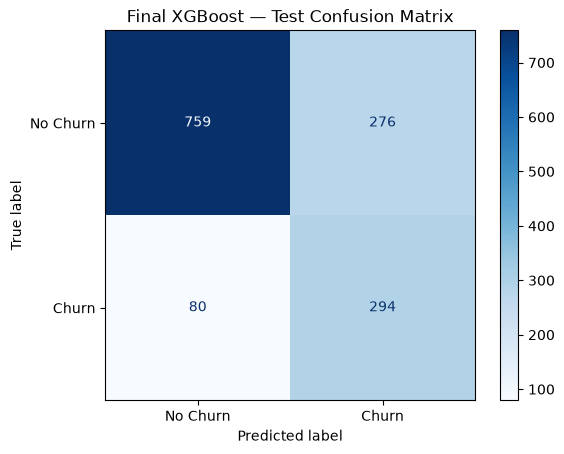

In [17]:
cm = confusion_matrix(y_test, test_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Final XGBoost — Test Confusion Matrix")
plt.show()

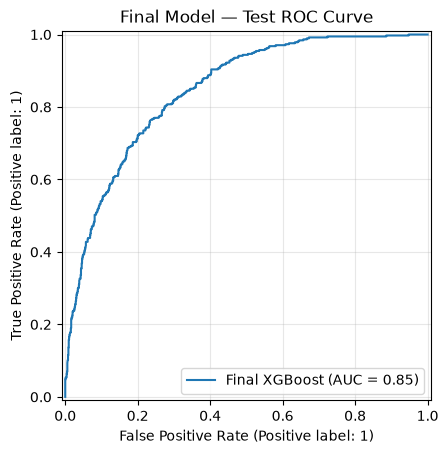

In [18]:
# ROC curve
RocCurveDisplay.from_predictions(
    y_test,
    test_proba,
    name="Final XGBoost"
)

plt.title("Final Model — Test ROC Curve")
plt.grid(alpha=0.3)
plt.show()

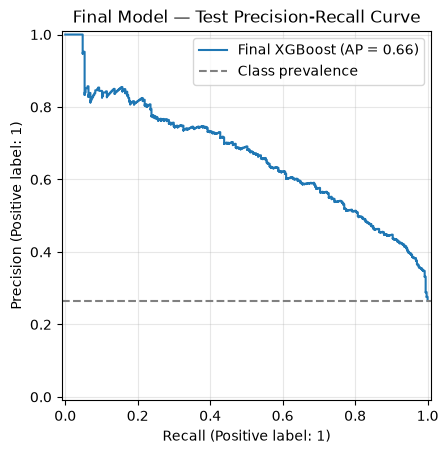

In [19]:
# Precision-Recall curve
PrecisionRecallDisplay.from_predictions(
    y_test,
    test_proba,
    name="Final XGBoost"
)

plt.axhline(
    y_test.mean(),
    color="gray",
    linestyle="--",
    label="Class prevalence"
)

plt.title("Final Model — Test Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 6. Export Final Evaluation Artifacts

The final test metrics, predictions, and evaluation
figures are exported for reproducibility and reporting.

The selected model and classification threshold
remain unchanged after test evaluation.

In [20]:
# Create output directories
results_dir = project_root / "results"
figures_dir = project_root / "figures" / "06"

results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

# Save final evaluation summary
final_results = {
    "model": "XGBoost",
    "threshold": float(loaded_threshold),
    "threshold_selection": "OOF F1 optimization",
    "test_samples": len(y_test),
    "alerts": int(test_pred.sum()),
    "alert_rate": float(test_pred.mean()),
    "metrics": {
        k: float(v)
        for k, v in test_metrics.items()
    },
    "confusion_matrix": {
        "tn": int(cm[0, 0]),
        "fp": int(cm[0, 1]),
        "fn": int(cm[1, 0]),
        "tp": int(cm[1, 1])
    }
}

metrics_path = results_dir / "06_final_test_metrics.json"

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(final_results, f, indent=4)

# Save final test predictions
test_predictions_df = pd.DataFrame({
    "y_true": np.asarray(y_test),
    "churn_probability": test_proba,
    "y_pred": test_pred
})

predictions_path = results_dir / "06_test_predictions.csv"

test_predictions_df.to_csv(
    predictions_path,
    index=False
)

print("Metrics saved:", metrics_path)
print("Predictions saved:", predictions_path)

Metrics saved: C:\Users\Lenovo\Desktop\DS\Customer_Churn\Teleco_Customer_Churn\results\06_final_test_metrics.json
Predictions saved: C:\Users\Lenovo\Desktop\DS\Customer_Churn\Teleco_Customer_Churn\results\06_test_predictions.csv


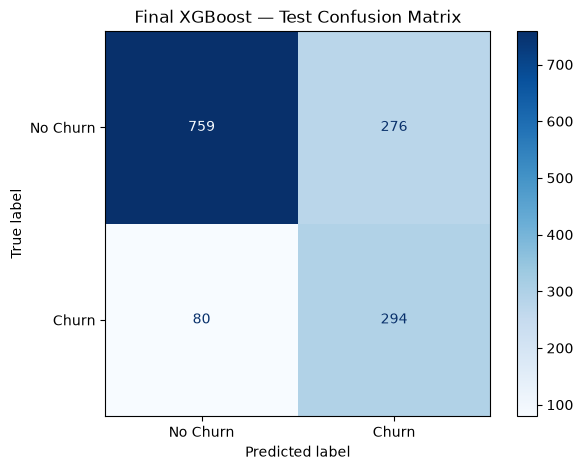

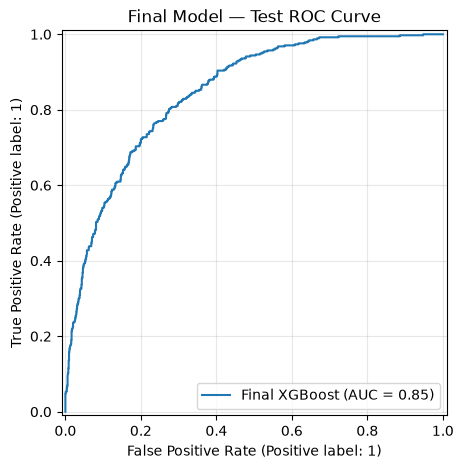

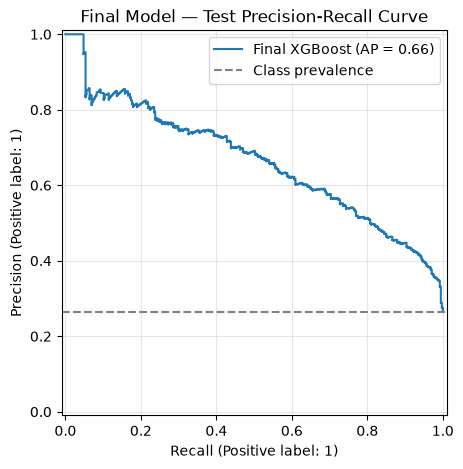

In [21]:
# Confusion Matrix
fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_pred,
    display_labels=["No Churn", "Churn"],
    cmap="Blues",
    values_format="d",
    ax=ax
)

ax.set_title("Final XGBoost — Test Confusion Matrix")
fig.savefig(
    figures_dir / "confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)


# ROC Curve
fig, ax = plt.subplots(figsize=(7, 5))

RocCurveDisplay.from_predictions(
    y_test,
    test_proba,
    name="Final XGBoost",
    ax=ax
)

ax.set_title("Final Model — Test ROC Curve")
ax.grid(alpha=0.3)

fig.savefig(
    figures_dir / "roc_curve.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)


# Precision-Recall Curve
fig, ax = plt.subplots(figsize=(7, 5))

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_proba,
    name="Final XGBoost",
    ax=ax
)

ax.axhline(
    y_test.mean(),
    color="gray",
    linestyle="--",
    label="Class prevalence"
)

ax.set_title("Final Model — Test Precision-Recall Curve")
ax.legend()
ax.grid(alpha=0.3)

fig.savefig(
    figures_dir / "precision_recall_curve.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
plt.close(fig)

In [22]:
exported_files = [
    metrics_path,
    predictions_path,
    figures_dir / "confusion_matrix.png",
    figures_dir / "roc_curve.png",
    figures_dir / "precision_recall_curve.png",
    model_path
]

for path in exported_files:
    assert path.exists(), f"Missing artifact: {path}"
    print("[OK]", path.relative_to(project_root))

assert len(test_predictions_df) == len(y_test)

print("\nAll final evaluation artifacts verified.")

[OK] results\06_final_test_metrics.json
[OK] results\06_test_predictions.csv
[OK] figures\06\confusion_matrix.png
[OK] figures\06\roc_curve.png
[OK] figures\06\precision_recall_curve.png
[OK] models\final_churn_model.joblib

All final evaluation artifacts verified.


## 7. Final Model Tracking with MLflow

The final optimized XGBoost model is logged to MLflow.

The tracking experiment records:
- Selected hyperparameters and classification threshold.
- Out-of-fold and final test metrics.
- Confusion matrix statistics.
- Serialized deployment-ready model artifact.
- Evaluation figures and test predictions.

The existing SQLite tracking backend is reused.

In [23]:


# Reuse the SQLite backend
db_path = project_root / "mlflow.db"

assert db_path.exists(), "MLflow database not found"

mlflow.set_tracking_uri(
    f"sqlite:///{db_path.as_posix()}"
)

experiment_name = "Telco_Churn_Final_Evaluation"

mlflow.set_experiment(experiment_name)

print("Tracking URI:", mlflow.get_tracking_uri())
print("Experiment:", experiment_name)

Tracking URI: sqlite:///C:/Users/Lenovo/Desktop/DS/Customer_Churn/Teleco_Customer_Churn/mlflow.db
Experiment: Telco_Churn_Final_Evaluation


In [24]:
with mlflow.start_run(
    run_name="XGBoost_Optimized_Final"
) as run:

    # Experiment metadata
    mlflow.set_tags({
        "project": "Telco Customer Churn",
        "stage": "final_evaluation",
        "model_family": "XGBoost"
    })

    # Model configuration
    mlflow.log_params(xgb_config)

    mlflow.log_params({
        "classification_threshold": float(loaded_threshold),
        "threshold_selection": "OOF_F1",
        "cv_folds": cv.get_n_splits(),
        "train_samples": len(X_train),
        "test_samples": len(X_test)
    })

    # OOF metrics
    mlflow.log_metrics({
        "oof_average_precision": float(oof_ap),
        "oof_roc_auc": float(oof_auc)
    })

    # Final test metrics
    mlflow.log_metrics({
        f"test_{name}": float(value)
        for name, value in test_metrics.items()
    })

    # Business-oriented metrics
    mlflow.log_metrics({
        "test_alerts": int(test_pred.sum()),
        "test_alert_rate": float(test_pred.mean()),
        "test_tp": int(cm[1, 1]),
        "test_fp": int(cm[0, 1]),
        "test_fn": int(cm[1, 0]),
        "test_tn": int(cm[0, 0])
    })

    # Save the deployment-ready model package
    mlflow.log_artifact(
        str(model_path),
        artifact_path="model"
    )

    # Save evaluation results
    mlflow.log_artifact(
        str(metrics_path),
        artifact_path="results"
    )

    mlflow.log_artifact(
        str(predictions_path),
        artifact_path="results"
    )

    # Save evaluation figures
    mlflow.log_artifacts(
        str(figures_dir),
        artifact_path="figures"
    )

    final_run_id = run.info.run_id

print("MLflow run completed.")
print("Run ID:", final_run_id)

MLflow run completed.
Run ID: 5f1c93c2ec774bb98122b0b55e8f3017


In [25]:
client = MlflowClient()

saved_run = mlflow.get_run(final_run_id)

assert saved_run.info.status == "FINISHED"

assert np.isclose(
    saved_run.data.metrics["test_f1"],
    test_metrics["f1"]
)

assert np.isclose(
    float(saved_run.data.params["classification_threshold"]),
    loaded_threshold
)

artifacts = client.list_artifacts(final_run_id)

print("Run status:", saved_run.info.status)
print("Test F1:", saved_run.data.metrics["test_f1"])
print("Test AP:", saved_run.data.metrics["test_average_precision"])
print("Artifacts:", [a.path for a in artifacts])

print("\nMLflow verification: PASSED")

Run status: FINISHED
Test F1: 0.6228813559322034
Test AP: 0.6645858371802413
Artifacts: ['figures', 'model', 'results']

MLflow verification: PASSED



## 8. Conclusion

### Final Model

The selected model is an **Optuna-optimized XGBoost classifier**, trained using a leakage-safe preprocessing pipeline.

The classification threshold was optimized using out-of-fold predictions from a stratified 5-fold cross-validation on the training set.

The final model was refitted on the complete training set and evaluated on the previously unseen test set.

### Final Test Performance

| Metric | Test Score |
|---|---:|
| Average Precision | 0.6646 |
| ROC-AUC | 0.8458 |
| Precision | 0.5158 |
| Recall | 0.7861 |
| F1-score | 0.6229 |
| Balanced Accuracy | 0.7597 |
| Classification Threshold | 0.2872 |

### Business Interpretation

The final model correctly identified **294 out of 374 actual churners**, achieving a recall of approximately 78.6%.

Among the 570 customers predicted to churn, 294 were actual churners and 276 were false positives.

The optimized threshold improves churn detection compared with the default threshold of 0.5 on the training OOF predictions, at the cost of additional false positives.

This trade-off may be useful for customer retention campaigns where missing a churner is costly. However, the optimal business threshold would require information about intervention costs, customer value, and campaign effectiveness.

### Generalization

The test Average Precision (0.6646) and ROC-AUC (0.8458) are close to their out-of-fold counterparts (0.6715 and 0.8503).

The test F1-score (0.6229) is slightly lower than the OOF F1-score (0.6408), suggesting reasonably stable predictive performance.

The OOF threshold was selected to maximize F1, so its performance estimate may be optimistic. The held-out test results provide the independent final evaluation.

### Limitations

- The threshold was selected using F1-score rather than an explicit business cost function.
- Approximately 48.4% of churn alerts are false positives.
- The model has not yet been evaluated for probability calibration or performance under data drift.
- The model has not yet been validated on a separate temporal or external dataset.

### Reproducibility

The final model, selected classification threshold, test metrics, predictions, and evaluation figures were saved as reusable artifacts.

MLflow was used to track the final experiment, including its configuration, evaluation metrics, and artifacts.

**The model and threshold are now frozen for deployment.**
